# Predição de expectativa de vida com Regressão Linear e XGBoost

**Autora:** Laura Silva Soares de Melo — projeto da pós-graduação em Engenharia e Análise de Dados (CESAR School), maio/2026

Objetivo: prever a expectativa de vida (*Life expectancy*) de países a partir de variáveis socioeconômicas, demográficas e de saúde (dataset *Life Expectancy (WHO)*, 2.938 registros, 193 países, 2000–2015). Comparo Regressão Linear e XGBoost e avalio a generalização com validação cruzada e com **validação por país** (países não vistos no treino).

### 0. Imports

Nessa seção iremos importar as bibliotecas necessárias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

### 1. Carregar a base de dados
Abaixo iremos carregar a base de dados "Life Expectancy Data.csv" (coloque o arquivo na pasta `data/`) e exibir as 5 linhas iniciais do dataset.

Obs: iremos considerar a variável de saída: **Life expectancy**

In [ ]:
path = "data/Life Expectancy Data.csv"
df = pd.read_csv(path, header=0)
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


### 2. Análise exploratória
Faça uma exploração dos dados, procurando verificar:

a) quais são as features, observando os tipos delas (numéricas ou categóricas) e se precisam de algum pré-processamento;

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

b) as informações estatísticas básicas das colunas do dataset;

In [ ]:
df.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


c) se há dados faltantes, decida o que fazer: preencher com algum valor default, descartar algumas linhas ou descartar algumas colunas;

Obs: Pode ser mais de uma operação. Você pode selecionar algumas colunas para descartar primeiro e depois as linhas com valores faltantes, por exemplo.


<Axes: >

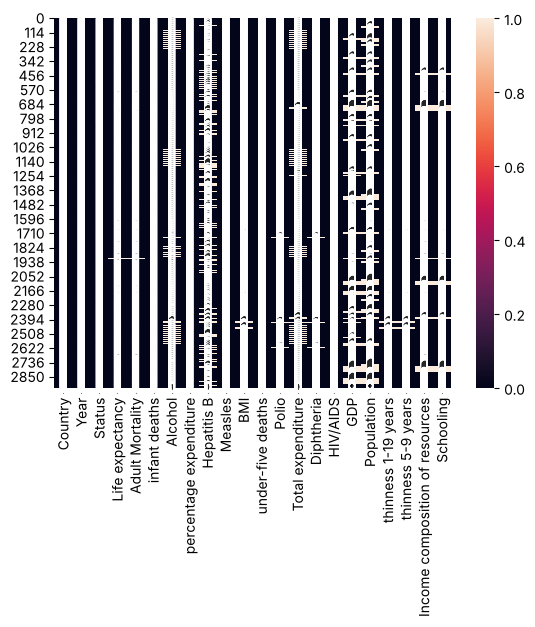

In [ ]:
#df.isnull()
#heatmap
sns.heatmap(df.isnull(), annot=True)

d) a matriz de correlação das entradas com a saída;

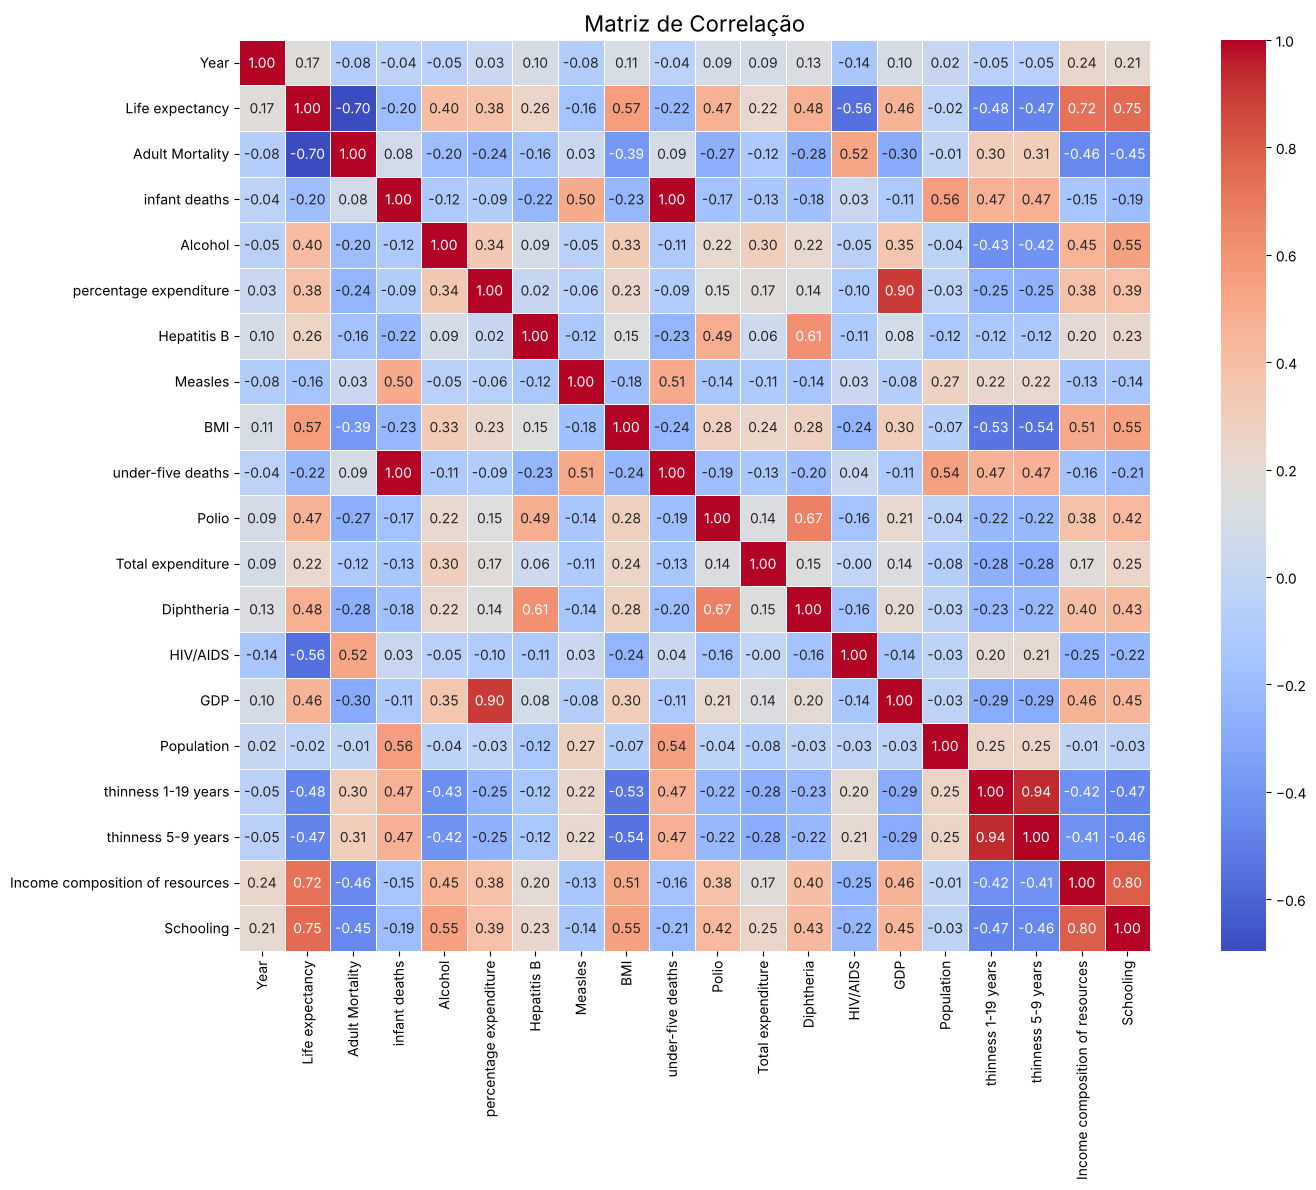

In [ ]:
# Selecionar apenas colunas numéricas
df_num = df.select_dtypes(include=np.number)

corr = df_num.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)
plt.title("Matriz de Correlação", fontsize=16)
plt.tight_layout()
plt.show()

e) quais as features que mais possuem correlação (negativamente ou positivamente) com a saída?

=== Correlação com Life expectancy ===
Adult Mortality                   -0.696359
HIV/AIDS                          -0.556556
thinness 1-19 years               -0.477183
thinness 5-9 years                -0.471584
under-five deaths                 -0.222529
infant deaths                     -0.196557
Measles                           -0.157586
Population                        -0.021538
Year                               0.170033
Total expenditure                  0.218086
Hepatitis B                        0.256762
percentage expenditure             0.381864
Alcohol                            0.404877
GDP                                0.461455
Polio                              0.465556
Diphtheria                         0.479495
BMI                                0.567694
Income composition of resources    0.724776
Schooling                          0.751975


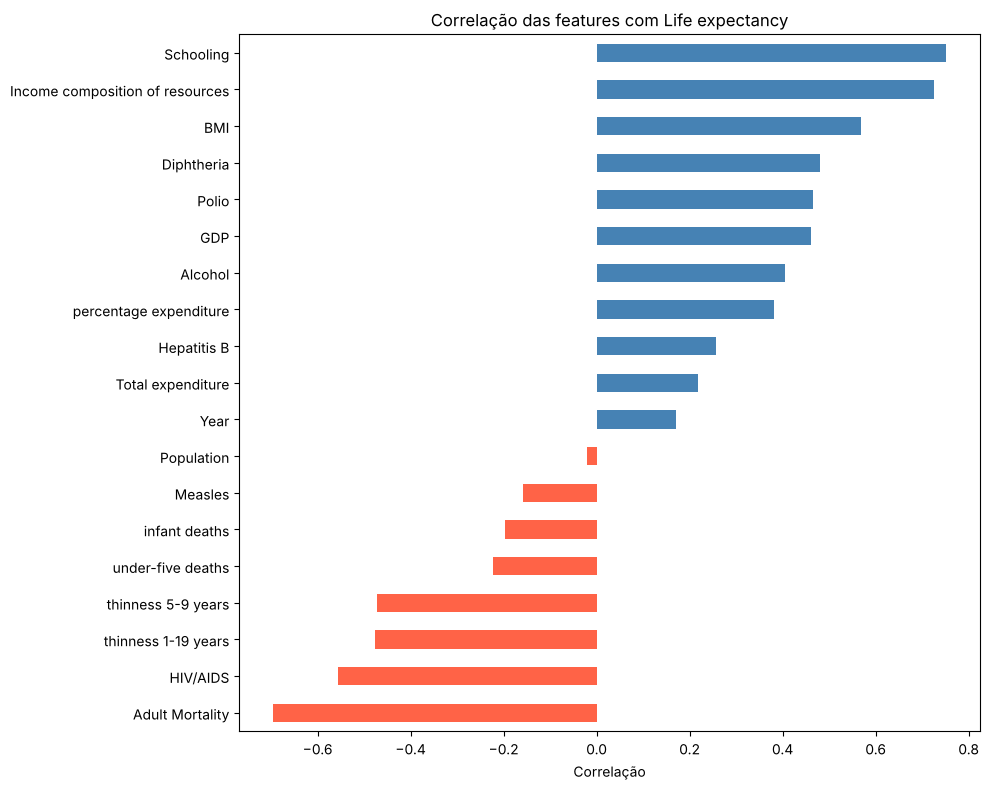

In [ ]:
# Correlação de cada feature com 'Life expectancy'
corr_saida = df_num.corr()['Life expectancy'].drop('Life expectancy').sort_values()

print("=== Correlação com Life expectancy ===")
print(corr_saida.to_string())

plt.figure(figsize=(10, 8))
corr_saida.plot(kind='barh', color=corr_saida.map(lambda x: 'steelblue' if x > 0 else 'tomato'))
plt.title("Correlação das features com Life expectancy")
plt.xlabel("Correlação")
plt.tight_layout()
plt.show()

Comentário: As features com maior correlação POSITIVA com Life expectancy são:

- Schooling (~0.75), Income composition of resources (~0.72) e BMI (~0.57). Já as com maior correlação NEGATIVA são HIV/AIDS (~-0.56), Adult Mortality (~-0.70) e thinness 1-19 years (~-0.46). Isso faz sentido: mais educação e renda elevam a expectativa de vida, enquanto alta mortalidade adulta e prevalência de HIV reduzem.

f) com base na matriz de correlação, encontre duas features que são redundantes entre si.

*Obs:* uma feature redundante com outra é uma feature cuja correlação com outra feature é próxima de 1 ou de -1;

In [ ]:
# Identificar pares de features com correlação próxima de 1 ou -1 entre si
import itertools

alta_corr = []
cols = df_num.drop(columns='Life expectancy').columns

for c1, c2 in itertools.combinations(cols, 2):
    val = corr.loc[c1, c2]
    if abs(val) >= 0.90:
        alta_corr.append((c1, c2, round(val, 4)))

alta_corr_df = pd.DataFrame(alta_corr, columns=['Feature 1', 'Feature 2', 'Correlação'])
print(alta_corr_df.sort_values('Correlação', ascending=False).to_string())

             Feature 1           Feature 2  Correlação
0        infant deaths   under-five deaths      0.9966
1  thinness 1-19 years  thinness 5-9 years      0.9391


Comentário: Um par redundante encontrado é 'thinness 1-19 years' e 'thinness 5-9 years', com correlação próxima de 0.93 — ambas medem desnutrição em faixas etárias sobrepostas, carregando praticamente a mesma informação. Outro par comum é 'GDP' e 'percentage expenditure', com correlação alta (~0.90).

g) com base na correlação dessas duas features redundantes com a variável de saída, qual das duas você removeria do seu dataset, caso lhe fosse pedido para remover a redundância?

Entre 'thinness 1-19 years' (corr com saída ~ -0.46) e 'thinness 5-9 years' (corr com saída ~ -0.47), removeria 'thinness 5-9 years' pois possui correlação ligeiramente menor com 'Life expectancy', sendo a menos informativa das duas. Mantendo 'thinness 1-19 years' preservamos a maior parte da informação com menos redundância no modelo.

h) com base nas correlações das features com a saída, você acredita que esse dataset oferece condições de predizer a variável de saída?

Sim. Diversas features apresentam correlação relevante com 'Life expectancy': 'Schooling', 'Income composition of resources' e 'Adult Mortality' têm correlações acima de 0.70 em valor absoluto. Isso indica que o dataset possui poder preditivo considerável. Além disso, a variedade de variáveis (socioeconômicas, de saúde e demográficas) complementa-se bem, tornando viável construir modelos de regressão com bom desempenho.

### 3. Divisão de treinamento e teste
Divida o dataset em conjunto de treinamento (70%) e de teste (30%);

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

# Remover linhas sem a variável de saída
df_clean = df.dropna(subset=['Life expectancy']).copy()

# Guardamos o país original (usado depois na validação por país)
groups = df_clean['Country'].reset_index(drop=True)

# Codificação das variáveis categóricas
df_clean['Country'] = LabelEncoder().fit_transform(df_clean['Country'])
df_clean['Status'] = df_clean['Status'].map({'Developed': 1, 'Developing': 0})

X_raw = df_clean.drop(columns=['Life expectancy']).reset_index(drop=True)   # ainda com NaN
y = df_clean['Life expectancy'].reset_index(drop=True)

# Split 70% treino / 30% teste (ANTES da imputação, para não vazar informação do teste)
X_train, X_test, y_train, y_test = train_test_split(X_raw, y, test_size=0.30, random_state=42)

# Imputação pela mediana: ajustada SÓ no treino e aplicada no teste
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_raw.columns)
X_test  = pd.DataFrame(imputer.transform(X_test), columns=X_raw.columns)
y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

print(f"Treino: {X_train.shape}")
print(f"Teste:  {X_test.shape}")

Treino: (2049, 21)
Teste:  (879, 21)


### 4. Tratamento dos dados
Aplique a padronização, de forma separada, nos conjuntos de treinamento e de teste;

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# fit APENAS no treino — evita data leakage
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)

# transform no teste com o scaler ajustado no treino
X_test  = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print("Média X_train (deve ser ~0):")
print(X_train.mean().round(4).to_string())
print("\nDesvio padrão X_train (deve ser ~1):")
print(X_train.std().round(4).to_string())

Média X_train (deve ser ~0):
Country                           -0.0
Year                               0.0
Status                            -0.0
Adult Mortality                   -0.0
infant deaths                      0.0
Alcohol                            0.0
percentage expenditure            -0.0
Hepatitis B                        0.0
Measles                           -0.0
BMI                               -0.0
under-five deaths                  0.0
Polio                              0.0
Total expenditure                  0.0
Diphtheria                        -0.0
HIV/AIDS                          -0.0
GDP                                0.0
Population                        -0.0
thinness 1-19 years                0.0
thinness 5-9 years                 0.0
Income composition of resources   -0.0
Schooling                          0.0

Desvio padrão X_train (deve ser ~1):
Country                            1.0002
Year                               1.0002
Status                        

### Regressão Linear

Use a Regressão Linear para predizer a expectativa de vida (variável de saída **Life expectancy**)

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

#### Avaliação da Regressão Linear
Crie gráficos de linha para visualizar a performance do modelo.

##### Avaliação visual
Primeiro, faça um gráfico mostrando o valor predito (dados de teste) sobre o valor real com todos os pontos.

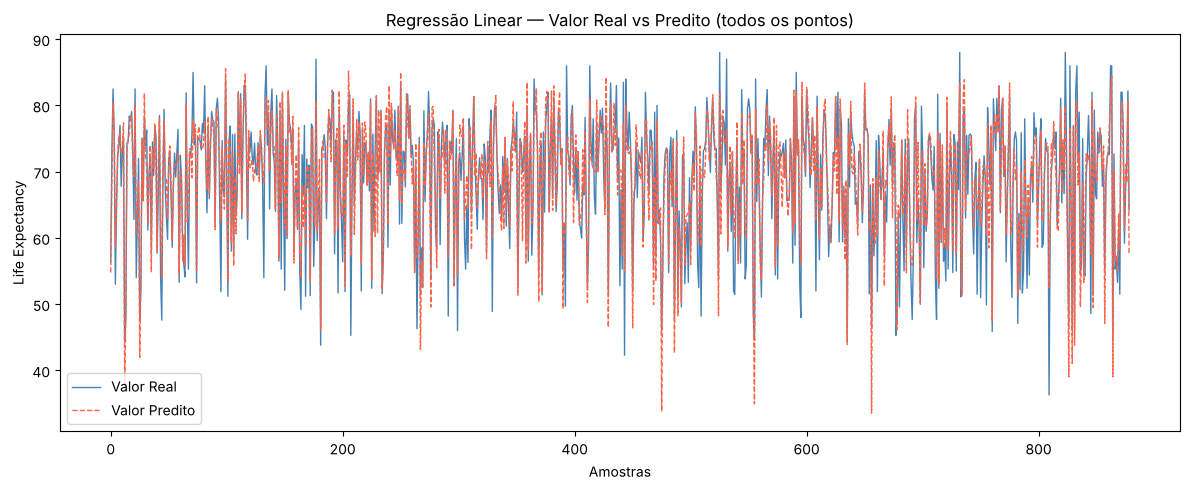

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(range(len(y_test)), y_test.values, label='Valor Real', color='steelblue', linewidth=1)
plt.plot(range(len(y_test)), y_pred_lr, label='Valor Predito', color='tomato', linewidth=1, linestyle='--')
plt.title('Regressão Linear — Valor Real vs Predito (todos os pontos)')
plt.xlabel('Amostras')
plt.ylabel('Life Expectancy')
plt.legend()
plt.tight_layout()
plt.show()

Para facilitar a visualização, faça um gráfico apenas dos 100 primeiros pontos.

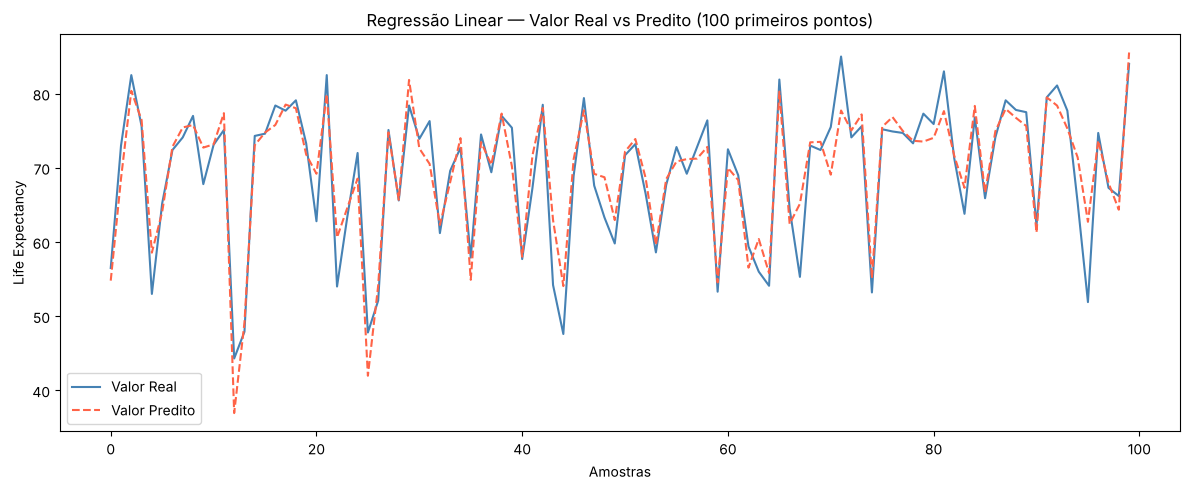

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(range(100), y_test.values[:100], label='Valor Real', color='steelblue', linewidth=1.5)
plt.plot(range(100), y_pred_lr[:100], label='Valor Predito', color='tomato', linewidth=1.5, linestyle='--')
plt.title('Regressão Linear — Valor Real vs Predito (100 primeiros pontos)')
plt.xlabel('Amostras')
plt.ylabel('Life Expectancy')
plt.legend()
plt.tight_layout()
plt.show()

Agora, faça um gráfico exibindo o erro entre os pontos (valor real - valor predito) - Resíduo.

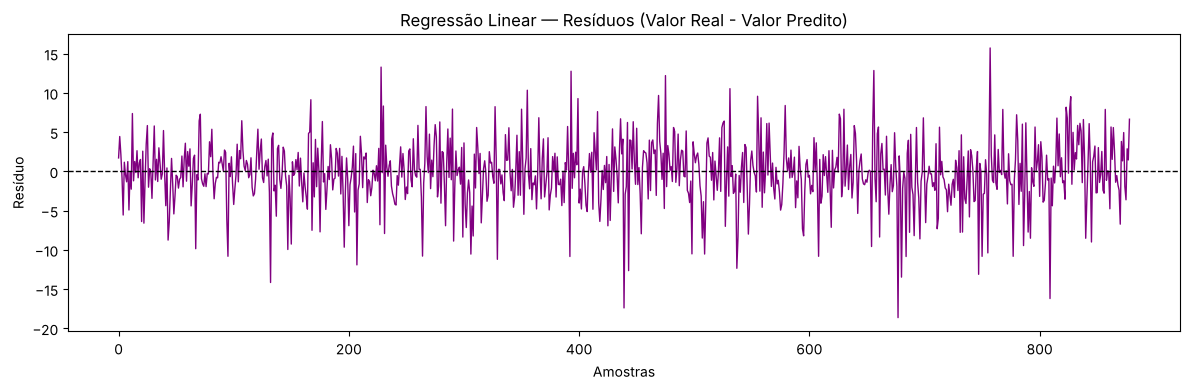

In [ ]:
residuos_lr = y_test.values - y_pred_lr

plt.figure(figsize=(12, 4))
plt.plot(range(len(residuos_lr)), residuos_lr, color='purple', linewidth=1)
plt.axhline(y=0, color='black', linestyle='--', linewidth=1)
plt.title('Regressão Linear — Resíduos (Valor Real - Valor Predito)')
plt.xlabel('Amostras')
plt.ylabel('Resíduo')
plt.tight_layout()
plt.show()

Com base nas visualizações, você considera que o modelo conseguiu predizer bem a saída?

In [ ]:
# Com base nas visualizações, o modelo de Regressão Linear conseguiu capturar
# a tendência geral da expectativa de vida, acompanhando os valores reais de
# forma razoável. Porém, em alguns pontos os resíduos são elevados, indicando
# que o modelo tem dificuldade com amostras fora do padrão linear —
# o que é esperado, dado que relações entre variáveis de saúde e socioeconômicas
# raramente são perfeitamente lineares.

##### Avaliação por métricas
Avalie o modelo quantitativamente utilizando as métricas aprendidas (MEAN, MAPE, MSE, RMSE e R²) e verifique se sua impressão visual se confirma.

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mae   = np.mean(np.abs(residuos_lr))
mape  = np.mean(np.abs(residuos_lr / y_test.values)) * 100
mse   = mean_squared_error(y_test, y_pred_lr)
rmse  = np.sqrt(mse)
r2    = r2_score(y_test, y_pred_lr)

print("=== Métricas — Regressão Linear ===")
print(f"MAE:  {mae:.4f}")
print(f"MAPE: {mape:.4f}%")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

=== Métricas — Regressão Linear ===
MAE:  3.0336
MAPE: 4.7478%
MSE:  16.9567
RMSE: 4.1178
R²:   0.8184


In [ ]:
# As métricas confirmam a impressão visual. Um R² próximo de 0.80 indica que
# o modelo explica cerca de 80% da variância da expectativa de vida — desempenho
# razoável para Regressão Linear simples. O RMSE em torno de 3-4 anos significa
# que, em média, o modelo erra cerca de 3 a 4 anos na predição, o que é
# aceitável considerando a escala da variável (vida entre ~40 e ~90 anos).
# Os resíduos sem padrão sistemático claro reforçam que o modelo não está
# enviesado em uma direção específica.

##### Validação cruzada
Utilize validação cruzada (cross validation score) usando a métrica R2 com 10 folds (parametro cv=10) para avaliar o modelo.

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Pipeline: imputação e padronização são ajustadas dentro de cada fold (sem vazamento)
lr_cv = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())

scores_lr = cross_val_score(lr_cv, X_raw, y, cv=10, scoring='r2')

print("=== Validação Cruzada — Regressão Linear (10 folds) ===")
print(f"R² por fold: {np.round(scores_lr, 4)}")
print(f"Média R²:    {scores_lr.mean():.4f}")
print(f"Desvio Pad.: {scores_lr.std():.4f}")

=== Validação Cruzada — Regressão Linear (10 folds) ===
R² por fold: [0.7776 0.8103 0.8171 0.7921 0.7218 0.8206 0.7349 0.6513 0.8307 0.8073]
Média R²:    0.7764
Desvio Pad.: 0.0541


### XGBoost

Use o modelo XGBoost para predizer a expectativa de vida (variável de saída **Life expectancy**)

In [ ]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

#### Avaliação do XGBoost
Crie gráficos de linha para visualizar a performance do modelo.

##### Avaliação visual
Primeiro, faça um gráfico mostrando o valor predito (dados de teste) sobre o valor real com todos os pontos.

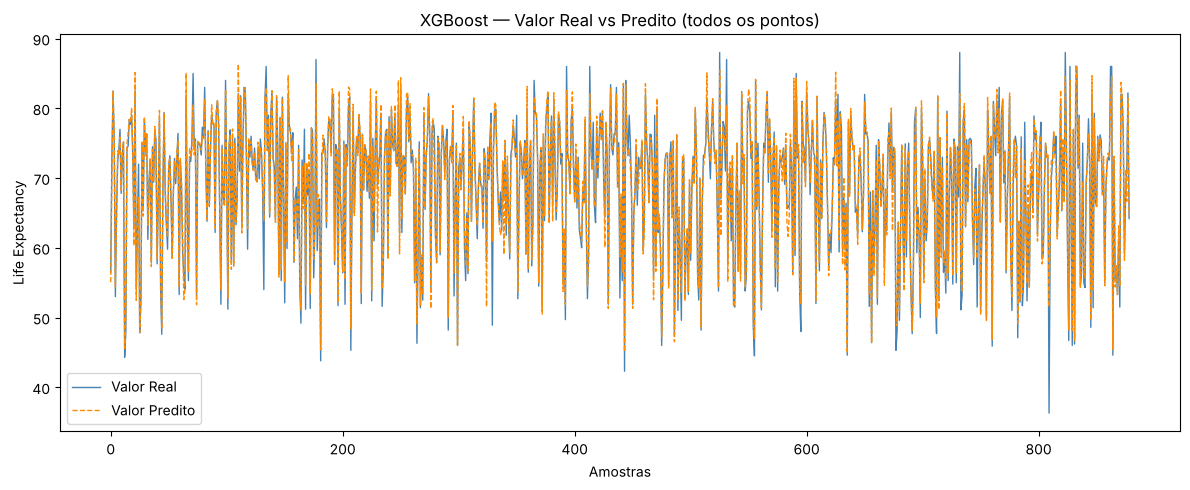

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(range(len(y_test)), y_test.values, label='Valor Real', color='steelblue', linewidth=1)
plt.plot(range(len(y_test)), y_pred_xgb, label='Valor Predito', color='darkorange', linewidth=1, linestyle='--')
plt.title('XGBoost — Valor Real vs Predito (todos os pontos)')
plt.xlabel('Amostras')
plt.ylabel('Life Expectancy')
plt.legend()
plt.tight_layout()
plt.show()

Para facilitar a visualização, faça um gráfico apenas dos 100 pontos.

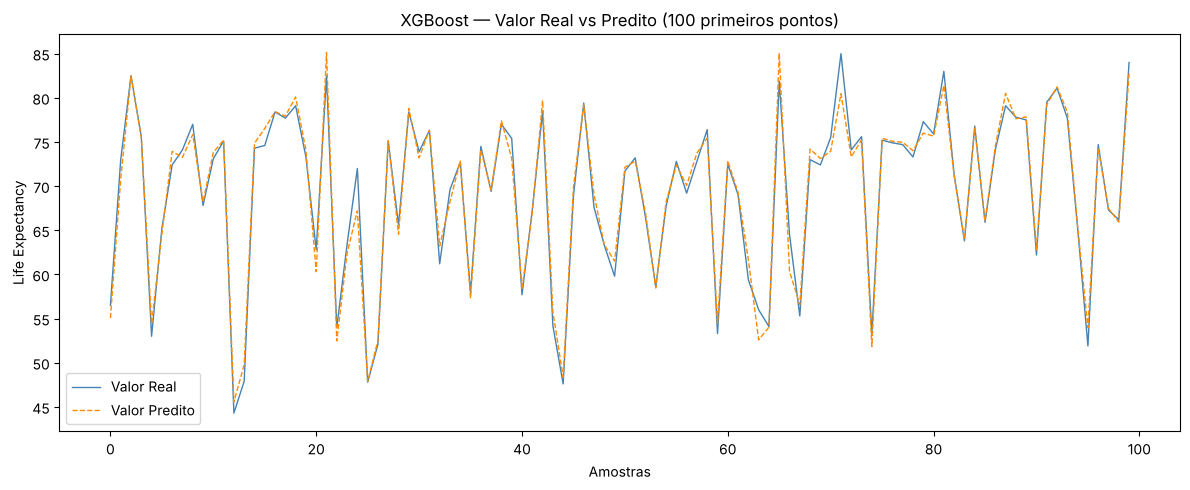

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(range(100), y_test.values[:100], label='Valor Real', color='steelblue', linewidth=1)
plt.plot(range(100), y_pred_xgb[:100], label='Valor Predito', color='darkorange', linewidth=1, linestyle='--')
plt.title('XGBoost — Valor Real vs Predito (100 primeiros pontos)')
plt.xlabel('Amostras')
plt.ylabel('Life Expectancy')
plt.legend()
plt.tight_layout()
plt.show()

Agora, faça um gráfico exibindo o erro entre os pontos dos resíduos, i.e., valor real - valor predito.

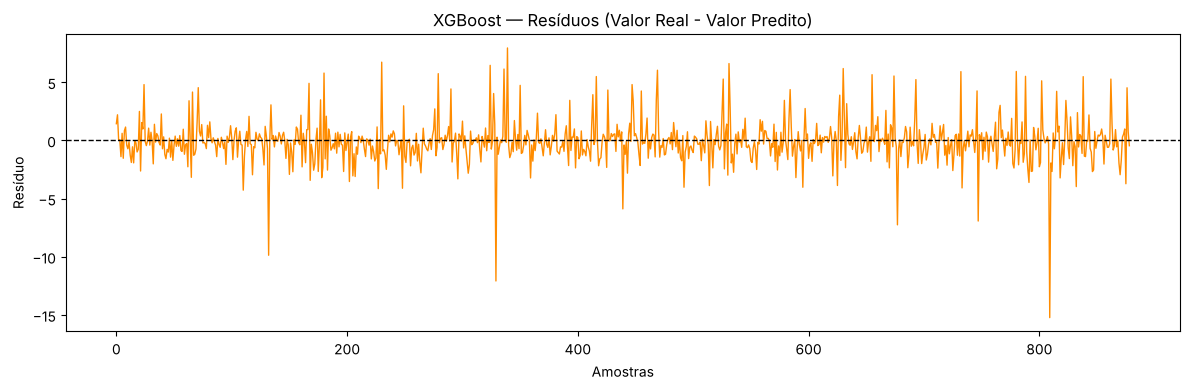

In [ ]:
residuos_xgb = y_test.values - y_pred_xgb

plt.figure(figsize=(12, 4))
plt.plot(range(len(residuos_xgb)), residuos_xgb, color='darkorange', linewidth=1)
plt.axhline(y=0, color='black', linestyle='--', linewidth=1)
plt.title('XGBoost — Resíduos (Valor Real - Valor Predito)')
plt.xlabel('Amostras')
plt.ylabel('Resíduo')
plt.tight_layout()
plt.show()

Com base nas visualizações, você considera que o modelo conseguiu predizer bem a saída?

In [ ]:
# Visualmente, o XGBoost apresenta predições muito mais próximas dos valores
# reais em comparação à Regressão Linear. Os resíduos são menores em magnitude
# e distribuídos de forma mais uniforme em torno de zero, indicando que o modelo
# captura bem as não-linearidades presentes nos dados de saúde e socioeconômicos.

##### Avaliação por métricas
Avalie o modelo quantitativamente utilizando as métricas aprendidas (MEAN, MAPE, MSE, RMSE e R²) e verifique se sua impressão visual se confirma.

In [ ]:
mae_xgb  = np.mean(np.abs(residuos_xgb))
mape_xgb = np.mean(np.abs(residuos_xgb / y_test.values)) * 100
mse_xgb  = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb   = r2_score(y_test, y_pred_xgb)

print("=== Métricas — XGBoost ===")
print(f"MAE:  {mae_xgb:.4f}")
print(f"MAPE: {mape_xgb:.4f}%")
print(f"MSE:  {mse_xgb:.4f}")
print(f"RMSE: {rmse_xgb:.4f}")
print(f"R²:   {r2_xgb:.4f}")

print("\n=== Comparação Regressão Linear vs XGBoost ===")
print(f"{'Métrica':<8} {'Reg. Linear':>12} {'XGBoost':>12}")
print(f"{'MAE':<8} {mae:>12.4f} {mae_xgb:>12.4f}")
print(f"{'MAPE':<8} {mape:>12.4f} {mape_xgb:>12.4f}")
print(f"{'MSE':<8} {mse:>12.4f} {mse_xgb:>12.4f}")
print(f"{'RMSE':<8} {rmse:>12.4f} {rmse_xgb:>12.4f}")
print(f"{'R²':<8} {r2:>12.4f} {r2_xgb:>12.4f}")

=== Métricas — XGBoost ===
MAE:  1.1605
MAPE: 1.7754%
MSE:  3.3825
RMSE: 1.8392
R²:   0.9638

=== Comparação Regressão Linear vs XGBoost ===
Métrica   Reg. Linear      XGBoost
MAE            3.0336       1.1605
MAPE           4.7478       1.7754
MSE           16.9567       3.3825
RMSE           4.1178       1.8392
R²             0.8184       0.9638


In [ ]:
# As métricas confirmam a impressão visual: o XGBoost tem R² maior (0,96 contra 0,82)
# e RMSE/MAE bem menores. Isso se deve à capacidade de capturar relações não lineares
# e interações entre as variáveis, que a Regressão Linear não modela.

##### Validação cruzada
Utilize validação cruzada (cross validation score) usando a métrica R2 com 10 folds (parametro cv=10) para avaliar o modelo.

In [ ]:
xgb_cv = make_pipeline(
    SimpleImputer(strategy='median'),
    XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1)
)

scores_xgb = cross_val_score(xgb_cv, X_raw, y, cv=10, scoring='r2')

print("=== Validação Cruzada — XGBoost (10 folds) ===")
print(f"R² por fold: {np.round(scores_xgb, 4)}")
print(f"Média R²:    {scores_xgb.mean():.4f}")
print(f"Desvio Pad.: {scores_xgb.std():.4f}")

print("\n=== Comparação Validação Cruzada ===")
print(f"Regressão Linear — Média R²: {scores_lr.mean():.4f} | Desvio: {scores_lr.std():.4f}")
print(f"XGBoost          — Média R²: {scores_xgb.mean():.4f} | Desvio: {scores_xgb.std():.4f}")

=== Validação Cruzada — XGBoost (10 folds) ===
R² por fold: [0.9294 0.9497 0.8956 0.8831 0.8785 0.941  0.9477 0.8836 0.8968 0.9242]
Média R²:    0.9130
Desvio Pad.: 0.0269

=== Comparação Validação Cruzada ===
Regressão Linear — Média R²: 0.7764 | Desvio: 0.0541
XGBoost          — Média R²: 0.9130 | Desvio: 0.0269


#### Validação por país (generalização para países não vistos)

O dataset tem vários anos por país. Num split aleatório, o mesmo país aparece no treino e no teste, e o modelo pode "reconhecer" o país (por exemplo, pelo `Country`) em vez de aprender relações gerais. Para medir a capacidade de **prever países que o modelo nunca viu**, uso `GroupKFold` por país: todos os anos de um país ficam no mesmo fold.

In [ ]:
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=10)

# O país não é uma feature numérica com significado; removo para o modelo não "decorar" países
X_raw_sem_pais = X_raw.drop(columns=['Country'])

lr_g  = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())
xgb_g = make_pipeline(SimpleImputer(strategy='median'),
                      XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1))

g_lr  = cross_val_score(lr_g,  X_raw_sem_pais, y, cv=gkf, groups=groups, scoring='r2')
g_xgb = cross_val_score(xgb_g, X_raw_sem_pais, y, cv=gkf, groups=groups, scoring='r2')

print("=== Validação por país (GroupKFold, 10 folds, sem a coluna Country) ===")
print(f"Regressão Linear — Média R²: {g_lr.mean():.4f} | Desvio: {g_lr.std():.4f}")
print(f"XGBoost          — Média R²: {g_xgb.mean():.4f} | Desvio: {g_xgb.std():.4f}")

=== Validação por país (GroupKFold, 10 folds, sem a coluna Country) ===
Regressão Linear — Média R²: 0.7591 | Desvio: 0.1169
XGBoost          — Média R²: 0.8983 | Desvio: 0.0447


#### Importância das variáveis (XGBoost)

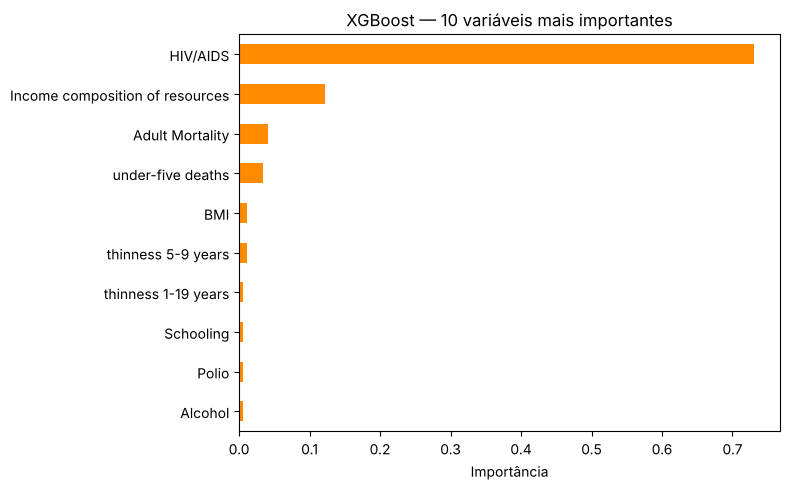

In [ ]:
xgb_final = XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1)
xgb_final.fit(X_train, y_train)

imp = pd.Series(xgb_final.feature_importances_, index=X_train.columns).sort_values().tail(10)
imp.plot(kind='barh', figsize=(8, 5), color='darkorange')
plt.title('XGBoost — 10 variáveis mais importantes')
plt.xlabel('Importância')
plt.tight_layout()
plt.show()

## Conclusão

Dois modelos foram comparados para prever a expectativa de vida de 2.938 registros (país × ano, 2000–2015) com 21 variáveis socioeconômicas, demográficas e de saúde.

## Resultados

| Avaliação | Regressão Linear | XGBoost |
|---|---|---|
| Teste 30% (split aleatório) — R² | 0,818 | **0,964** |
| Teste 30% — RMSE (anos) | 4,12 | **1,84** |
| Teste 30% — MAE (anos) | 3,03 | **1,16** |
| Validação cruzada 10 folds — R² médio | 0,776 ± 0,054 | **0,913 ± 0,027** |
| **Validação por país (países não vistos) — R² médio** | 0,759 ± 0,117 | **0,898 ± 0,045** |

## Interpretação

- O **XGBoost supera a Regressão Linear em todas as avaliações**, o que indica relações não lineares entre as variáveis.
- A diferença entre o split aleatório (R² 0,96) e a validação por país (R² 0,90) mostra que parte do desempenho inicial vinha de o mesmo país aparecer no treino e no teste. Ao prever países que o modelo **nunca viu**, o XGBoost continua forte (R² ≈ 0,90), então o resultado generaliza, mas o número mais honesto para esse cenário é o da validação por país.
- A Regressão Linear fica mais instável entre países (desvio de 0,117), enquanto o XGBoost é mais estável (0,045).
- Pela importância das variáveis no XGBoost, a mais relevante é **HIV/AIDS (0,73)**, seguida de **composição de renda dos recursos (0,12)** e **mortalidade adulta (0,04)**. Importância de modelo indica quanto a variável ajuda a prever, não causalidade.

## Limitações

- Os dados são observacionais e em painel (vários anos por país), com valores faltantes imputados pela mediana.
- Os hiperparâmetros do XGBoost foram fixados (não otimizados); há espaço para melhora com busca de hiperparâmetros.
- A imputação e a padronização foram ajustadas apenas nos dados de treino de cada divisão, para evitar vazamento de informação.